# Project :- Global Pollutiion Recorvery analysis 

# Import libraries 

In [28]:
import pandas as pd  # work with the dataset
import numpy as np  # numerical calculations
import matplotlib.pyplot as plt  # visualization
from sklearn.preprocessing import LabelEncoder, MinMaxScaler  # encoding and scaling

df = pd.read_csv("/Users/shyamalkar/Desktop/ML_project/08_Global_Pollution_Analysis_and_Energy_Recovery/Global_Pollution_Analysis (3).csv")  # load dataset

print(df.shape)  # check dataset size
df.head()  # view first rows

(200, 13)


,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


# Check missing values 

In [29]:
print("Missing values:\n", df.isnull().sum())  # check missing values
print("Duplicates:", df.duplicated().sum())  # check duplicate rows

Missing values:
 Country                                   0
Year                                      0
Air_Pollution_Index                       0
Water_Pollution_Index                     0
Soil_Pollution_Index                      0
Industrial_Waste (in tons)                0
Energy_Recovered (in GWh)                 0
CO2_Emissions (in MT)                     0
Renewable_Energy (%)                      0
Plastic_Waste_Produced (in tons)          0
Energy_Consumption_Per_Capita (in MWh)    0
Population (in millions)                  0
GDP_Per_Capita (in USD)                   0
dtype: int64
Duplicates: 0


 # Encode Country and Year 

In [30]:
country_encoder = LabelEncoder()  # create country encoder
year_encoder = LabelEncoder()  # create year encoder

df["Country_Encoded"] = country_encoder.fit_transform(df["Country"])  # encode country
df["Year_Encoded"] = year_encoder.fit_transform(df["Year"].astype(str))  # encode year

# Normalize Pollution Indices 

In [31]:
pollution_cols = [
    "Air_Pollution_Index",
    "Water_Pollution_Index",
    "Soil_Pollution_Index"
]

scaler = MinMaxScaler()  # create normalization scaler

df[pollution_cols] = scaler.fit_transform(
    df[pollution_cols]
)  # normalize pollution values between 0 and 1

# Energy Consumption per capita 

In [32]:
df["Energy_Consumption_Per_Capita (in MWh)"].describe()

count    200.00000
mean       9.43575
std        5.57567
min        0.53000
25%        4.58250
50%        9.22500
75%       13.99750
max       19.98000
Name: Energy_Consumption_Per_Capita (in MWh), dtype: float64

# Pollution Severity

In [33]:
df["Air_Severity"] = pd.qcut(
    df["Air_Pollution_Index"],
    3,
    labels=["Low", "Medium", "High"]
)  # categorize air pollution

df["Water_Severity"] = pd.qcut(
    df["Water_Pollution_Index"],
    3,
    labels=["Low", "Medium", "High"]
)  # categorize water pollution

df["Soil_Severity"] = pd.qcut(
    df["Soil_Pollution_Index"],
    3,
    labels=["Low", "Medium", "High"]
)  # categorize soil pollution

# Categorize energy recorvery 

In [34]:
df["Energy_Recovery_Level"] = pd.qcut(
    df["Energy_Recovered (in GWh)"],
    3,
    labels=["Low", "Medium", "High"]
)  # categorize energy recovery

In [35]:
# Similarly, Energy Consumption

df["Energy_Consumption_Level"] = pd.qcut(
    df["Energy_Consumption_Per_Capita (in MWh)"],
    3,
    labels=["Low", "Medium", "High"]
)  # categorize energy consumption

# Pollution Trend 

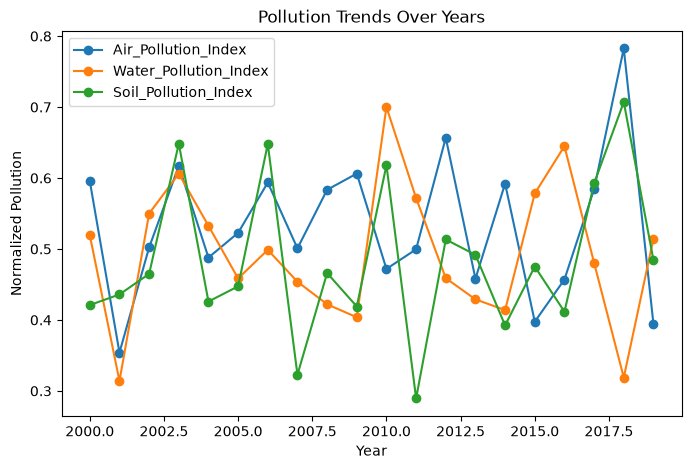

In [36]:
trend = df.groupby("Year")[pollution_cols].mean()  # calculate yearly average pollution

trend.plot(figsize=(8, 5), marker="o")  # plot pollution trends

plt.title("Pollution Trends Over Years")
plt.xlabel("Year")
plt.ylabel("Normalized Pollution")
plt.show()

# Apriori Algorithm 

In [37]:
from mlxtend.frequent_patterns import apriori, association_rules

# Transaction data 

In [38]:
basket = pd.get_dummies(
    df[
        [
            "Air_Severity",
            "Water_Severity",
            "Soil_Severity",
            "Energy_Recovery_Level",
            "Energy_Consumption_Level"
        ]
    ].astype(str)
)  # convert categories into 0/1 transaction format

In [39]:
# Check 

basket.head()

,Air_Severity_High,Air_Severity_Low,Air_Severity_Medium,Water_Severity_High,Water_Severity_Low,Water_Severity_Medium,Soil_Severity_High,Soil_Severity_Low,Soil_Severity_Medium,Energy_Recovery_Level_High,Energy_Recovery_Level_Low,Energy_Recovery_Level_Medium,Energy_Consumption_Level_High,Energy_Consumption_Level_Low,Energy_Consumption_Level_Medium
0,True,False,False,False,False,True,False,True,False,False,True,False,True,False,False
1,False,True,False,False,True,False,True,False,False,True,False,False,False,True,False
2,False,True,False,False,True,False,True,False,False,True,False,False,True,False,False
3,True,False,False,False,True,False,False,False,True,False,True,False,False,True,False
4,False,False,True,False,False,True,True,False,False,False,True,False,True,False,False


# Find frequent itemsets


In [40]:
frequent_itemsets = apriori(
    basket,
    min_support=0.10,
    use_colnames=True
)  # find item combinations appearing in at least 10% of transactions

In [41]:
frequent_itemsets.sort_values(
    "support",
    ascending=False
).head(10)

,support,itemsets
0,0.335,frozenset({Air_Severity_High})
7,0.335,frozenset({Soil_Severity_Low})
1,0.335,frozenset({Air_Severity_Low})
13,0.335,frozenset({Energy_Consumption_Level_Low})
12,0.335,frozenset({Energy_Consumption_Level_High})
10,0.335,frozenset({Energy_Recovery_Level_Low})
9,0.335,frozenset({Energy_Recovery_Level_High})
6,0.335,frozenset({Soil_Severity_High})
4,0.335,frozenset({Water_Severity_Low})
3,0.335,frozenset({Water_Severity_High})


`Just Replace that part with this:`

In [56]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.50
)  # generate rules with all metrics

energy_rules = rules.loc[
    rules["consequents"].apply(
        lambda x: "Energy_Recovery_Level_High" in x
    ),
    ["antecedents", "consequents", "support", "confidence", "lift"]
].sort_values(
    "lift",
    ascending=False
)

energy_rules.head(10)

,antecedents,consequents,support,confidence,lift


In [50]:
print(rules.columns)

Index(['antecedents', 'consequents', 'antecedent support',
       'consequent support', 'support', 'confidence', 'lift',
       'representativity', 'leverage', 'conviction', 'zhangs_metric',
       'jaccard', 'certainty', 'kulczynski'],
      dtype='str')


In [57]:
print(rules["consequents"].head(20))

Series([], Name: consequents, dtype: object)


# Model Evaluation & Validation 

In [58]:
from sklearn.model_selection import train_test_split  # split transactions

train_basket, test_basket = train_test_split(
    basket,
    test_size=0.20,
    random_state=42
)  # 80% training, 20% testing

`Mine Rules using training data`

In [59]:
train_itemsets = apriori(
    train_basket,
    min_support=0.10,
    use_colnames=True
)  # find frequent itemsets from training data

train_rules = association_rules(
    train_itemsets,
    metric="confidence",
    min_threshold=0.50
)  # generate association rules

# Check the strong training rules

In [60]:
train_rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].sort_values(
    "lift",
    ascending=False
).head(10)

,antecedents,consequents,support,confidence,lift


# Validation rules on the test data 

In [61]:
def test_rule_metrics(rule, data):
    A = list(rule["antecedents"])
    B = list(rule["consequents"])

    a = data[A].all(axis=1)
    b = data[B].all(axis=1)

    support = (a & b).mean()
    confidence = support / a.mean() if a.mean() > 0 else 0
    lift = confidence / b.mean() if b.mean() > 0 else 0

    return support, confidence, lift

In [77]:
from sklearn.model_selection import KFold  # create folds

kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold, (train_idx, _) in enumerate(kf.split(basket), 1):
    fold_data = basket.iloc[train_idx]

    itemsets = apriori(
        fold_data,
        min_support=0.10,
        use_colnames=True
    )

    fold_rules = association_rules(
        itemsets,
        metric="confidence",
        min_threshold=0.50
    )

    fold_results.append({
        "Fold": fold,
        "Frequent_Itemsets": len(itemsets),
        "Rules": len(fold_rules)
    })

fold_results = pd.DataFrame(fold_results)

fold_results

,Fold,Frequent_Itemsets,Rules
0,1,83,0
1,2,89,0
2,3,87,0
3,4,87,0
4,5,90,0


 # Interpret Validation 

In [79]:
print("Average Rules:", round(fold_results["Rules"].mean(), 2))
print("Average Frequent Itemsets:", round(fold_results["Frequent_Itemsets"].mean(), 2))

Average Rules: 0.0
Average Frequent Itemsets: 87.2


# Simple 5-Fold Validation 

In [80]:
from sklearn.model_selection import KFold  # create folds

kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold, (train_idx, _) in enumerate(kf.split(basket), 1):
    fold_data = basket.iloc[train_idx]

    itemsets = apriori(
        fold_data,
        min_support=0.10,
        use_colnames=True
    )

    fold_rules = association_rules(
        itemsets,
        metric="confidence",
        min_threshold=0.50
    )

    fold_results.append({
        "Fold": fold,
        "Frequent_Itemsets": len(itemsets),
        "Rules": len(fold_rules)
    })

pd.DataFrame(fold_results)

,Fold,Frequent_Itemsets,Rules
0,1,83,0
1,2,89,0
2,3,87,0
3,4,87,0
4,5,90,0


# Phase 4 - Reporting & Insights 

In [83]:
top_rules = train_rules.sort_values(
    "lift",
    ascending=False
).head(10)  # select the 10 strongest rules

In [84]:
top_rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
]

,antecedents,consequents,support,confidence,lift


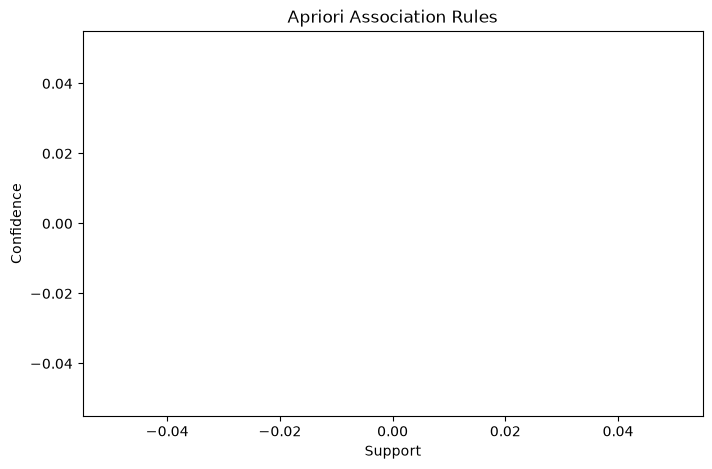

In [85]:
plt.figure(figsize=(8, 5))

plt.scatter(
    top_rules["support"],
    top_rules["confidence"],
    s=top_rules["lift"] * 30
)

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Apriori Association Rules")

plt.show()

In [87]:
strong_rules = train_rules[
    (train_rules["confidence"] >= 0.60) &
    (train_rules["lift"] > 1)
].sort_values(
    "lift",
    ascending=False
)

strong_rules[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(10)

,antecedents,consequents,support,confidence,lift


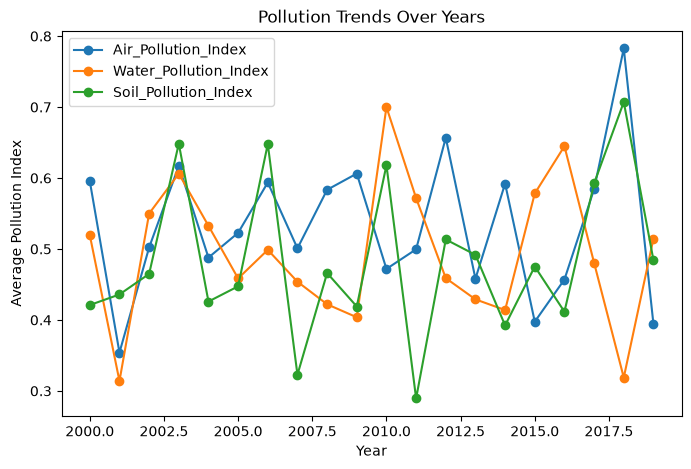

In [88]:
trend = df.groupby("Year")[
    [
        "Air_Pollution_Index",
        "Water_Pollution_Index",
        "Soil_Pollution_Index"
    ]
].mean()

trend.plot(
    figsize=(8, 5),
    marker="o"
)

plt.title("Pollution Trends Over Years")
plt.xlabel("Year")
plt.ylabel("Average Pollution Index")
plt.show()

# Summary 

# Phase 4 — Reporting and Insights

## Apriori Findings

The Apriori algorithm was used to identify associations between pollution severity, energy consumption, and energy recovery.

The discovered rules were evaluated using support, confidence, and lift.

- Support shows how frequently an item combination occurs.
- Confidence shows how often the consequent occurs when the antecedent occurs.
- Lift measures the strength of the association.
- Lift greater than 1 indicates a positive association.

## Energy Recovery

The strongest rules associated with high energy recovery were analyzed to identify pollution and energy-consumption conditions that frequently occur together with high energy recovery.

These results represent associations and do not prove that pollution causes energy recovery.

## Pollution Trends

Air, water, and soil pollution were analyzed across different years to identify changes in pollution levels over time.

## Recommendations

1. Monitor pollution conditions associated with strong positive Apriori rules.
2. Identify opportunities for energy recovery in high-pollution environments.
3. Improve pollution-control strategies based on recurring pollution patterns.
4. Optimize energy recovery from industrial waste and other recoverable resources.
5. Use larger real-world datasets to generate more reliable association rules.
6. Treat Apriori rules as decision-support information rather than causal conclusions.
